<a href="https://colab.research.google.com/github/DunyaVatandasi/abd-borsa-calismalari/blob/main/01_hareketli_ortalamalar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import yfinance as yf
import matplotlib.pyplot as plt

def hisse_analiz(sembol, period="5y"):
    # 1) Veriyi çek
    veri = yf.Ticker(sembol).history(period=period)
    if veri.empty:
        print(f"{sembol} için veri bulunamadı. Sembolü kontrol et.")
        return None

    # 2) Göstergeleri hesapla
    veri["SMA50"] = veri["Close"].rolling(50).mean()
    veri["SMA200"] = veri["Close"].rolling(200).mean()
    veri["Uzaklik"] = (veri["Close"] / veri["SMA50"] - 1) * 100

    uz = veri["Uzaklik"].dropna()
    son_uz = uz.iloc[-1]
    yuzdelik = (uz < son_uz).mean() * 100

    # 3) Raporu yazdır
    print(f"===== {sembol} | Dönem: {period} =====")
    print(f"Son fiyat         : {veri['Close'].iloc[-1]:.2f} $")
    print(f"SMA50'ye uzaklık  : %{son_uz:.1f}")
    print(f"Dönemdeki aralık  : %{uz.min():.1f} ile %{uz.max():.1f}")
    print(f"Yüzdelik dilim    : geçmiş günlerin %{yuzdelik:.0f}'inden yüksek")

    # 4) Trend ve son kesişme (SMA200 için en az 200 gün gerekir)
    fark = (veri["SMA50"] - veri["SMA200"]).dropna()
    if fark.empty:
        print("Trend             : SMA200 için veri yetersiz, daha uzun dönem seç")
    else:
        yukari = fark > 0
        trend = "YUKARI (SMA50 > SMA200)" if yukari.iloc[-1] else "AŞAĞI (SMA50 < SMA200)"
        print(f"Uzun vadeli trend : {trend}")
        kesismeler = yukari[yukari != yukari.shift()].iloc[1:]
        if len(kesismeler) > 0:
            tur = "Golden Cross" if kesismeler.iloc[-1] else "Death Cross"
            print(f"Son kesişme       : {tur} ({kesismeler.index[-1].date()})")
        else:
            print("Son kesişme       : Dönem içinde kesişme yok")

    # 5) Grafikler
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True,
                                   gridspec_kw={"height_ratios": [2, 1]})
    veri[["Close", "SMA50", "SMA200"]].plot(ax=ax1, title=f"{sembol} - Fiyat ve Hareketli Ortalamalar")
    uz.plot(ax=ax2, title="SMA50'ye Uzaklık (%)", color="purple")
    ax2.axhline(0, color="gray", linestyle="--")
    plt.tight_layout()
    plt.show()

    return veri

===== AAPL | Dönem: 5y =====
Son fiyat         : 356.27 $
SMA50'ye uzaklık  : %5.2
Dönemdeki aralık  : %-24.0 ile %17.6
Yüzdelik dilim    : geçmiş günlerin %69'inden yüksek
Uzun vadeli trend : YUKARI (SMA50 > SMA200)
Son kesişme       : Golden Cross (2025-09-15)


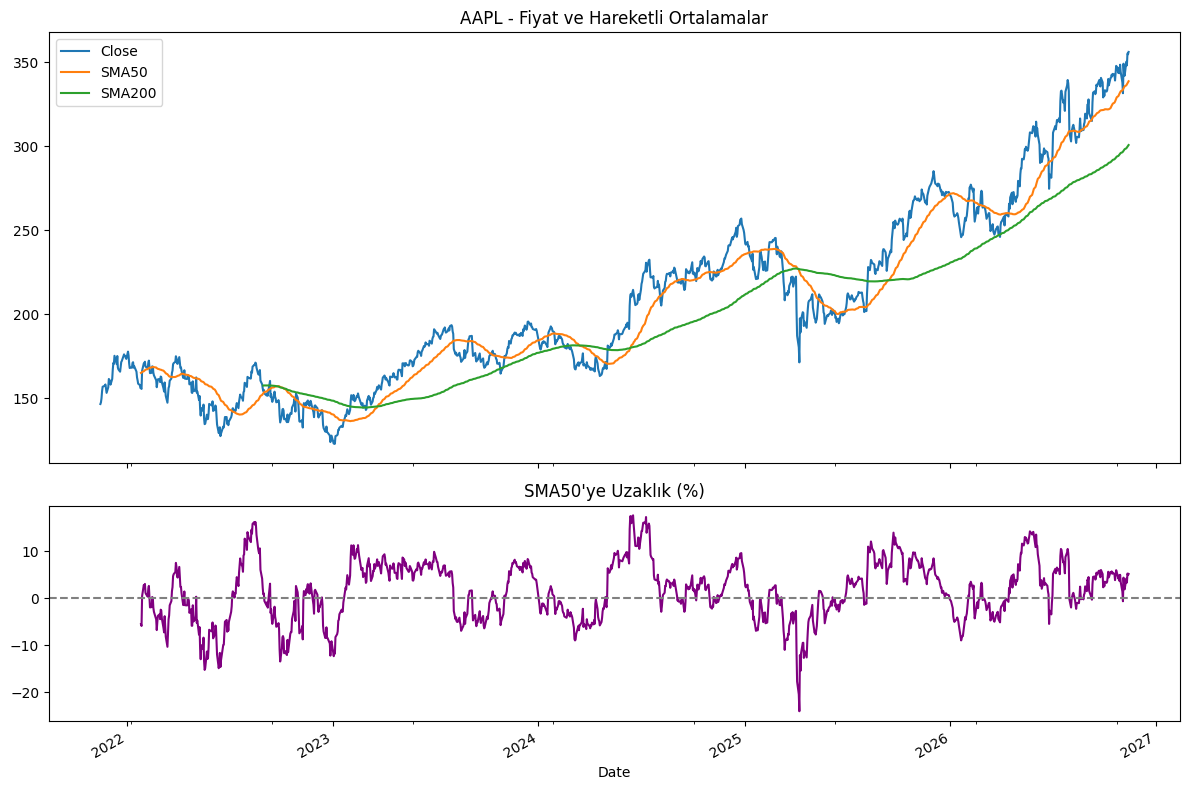

===== NVDA | Dönem: 2y =====
Son fiyat         : 162.85 $
SMA50'ye uzaklık  : %-24.1
Dönemdeki aralık  : %-24.1 ile %22.6
Yüzdelik dilim    : geçmiş günlerin %0'inden yüksek
Uzun vadeli trend : YUKARI (SMA50 > SMA200)
Son kesişme       : Dönem içinde kesişme yok


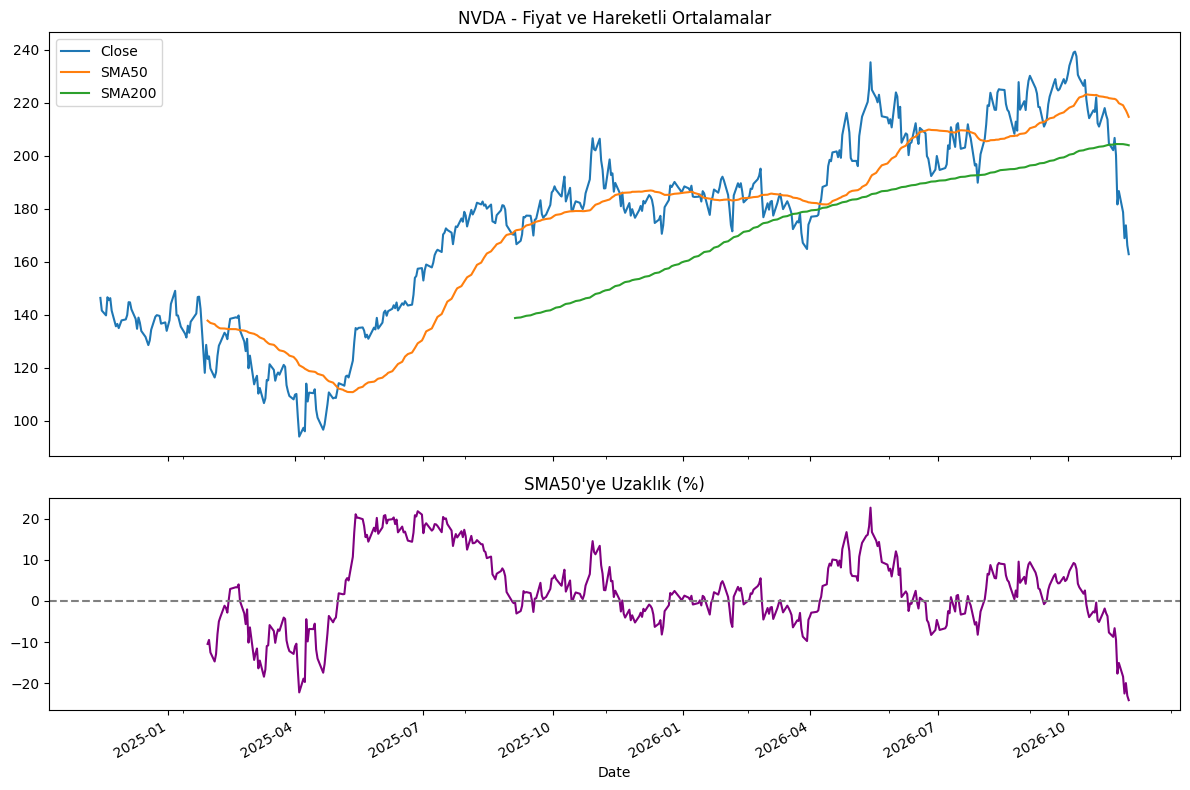

,Open,High,Low,Close,Volume,Dividends,Stock Splits,SMA50,SMA200,Uzaklik
Date,,,,,,,,,,
2024-11-14 00:00:00-05:00,147.244898,148.601260,145.160495,146.367249,194463300,0.0,0.0,NaN,NaN,NaN
2024-11-15 00:00:00-05:00,144.482318,144.851338,139.705142,141.600052,250132900,0.0,0.0,NaN,NaN,NaN
2024-11-18 00:00:00-05:00,139.126694,141.171211,136.782976,139.774948,221205300,0.0,0.0,NaN,NaN,NaN
2024-11-19 00:00:00-05:00,140.941832,146.736282,140.612713,146.616592,227834900,0.0,0.0,NaN,NaN,NaN
2024-11-20 00:00:00-05:00,147.015525,147.165117,142.348041,145.499588,309871700,0.0,0.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
2026-11-09 00:00:00-05:00,173.070007,179.919998,170.240005,178.669998,462719300,0.0,0.0,219.000486,204.348143,-18.415707
2026-11-10 00:00:00-05:00,173.970001,174.690002,165.889999,168.889999,429273200,0.0,0.0,217.967621,204.262420,-22.516015
2026-11-11 00:00:00-05:00,172.800003,177.539993,170.770004,173.729996,339214800,0.0,0.0,217.098282,204.190670,-19.976338


In [2]:
hisse_analiz("AAPL")
hisse_analiz("NVDA", "2y")